In [ ]:
import torch
import matplotlib.pyplot as plt

1.1 Решить с использованием автоматического градиента баллистическую задачу (найти скорость , ускорение и координаты для тела брошенного под углом 45 гр с начальной координатой h=3m и начальной скоростью v0 = 10m/c2)

In [ ]:
v0 = 10.0
angle = 45.0
x0 = 0.0
h = 3.0
g = 9.81

angle_rad = torch.tensor(angle*torch.pi / 180)
v0x = v0 * torch.cos(angle_rad)
v0y = v0 * torch.sin(angle_rad)

ax0 = 0.0
ay0 = -g

t_end = (v0y + torch.sqrt(v0y**2 + 2*g*h)) / g
t = torch.linspace(0, t_end.item(), 50, requires_grad=True)

x = x0 + v0x*t + ax0*t**2 / 2
y = h + v0y*t + ay0*t**2 / 2

vx = torch.autograd.grad(x, t, grad_outputs=torch.ones_like(x), create_graph=True)[0]
vy = torch.autograd.grad(y, t, grad_outputs=torch.ones_like(y), create_graph=True)[0]
v = torch.sqrt(vx**2 + vy**2)

ax = torch.autograd.grad(vx, t, grad_outputs=torch.ones_like(vx))[0]
ay = torch.autograd.grad(vy, t, grad_outputs=torch.ones_like(vy))[0]

print(f"Время полета (в секундах): {t_end.item():.3f}")
print(f"{'t, с':>7} {'x, м':>9} {'y, м':>9} {'vx, м/с':>10} {'vy, м/с':>10} {'v, м/с':>10} {'ax, м/с²':>11} {'ay, м/с²':>11}")

for i in range(len(t)):
    print(
        f"{t[i].item():7.3f} "
        f"{x[i].item():9.3f} "
        f"{y[i].item():9.3f} "
        f"{vx[i].item():10.3f} "
        f"{vy[i].item():10.3f} "
        f"{v[i].item():10.3f} "
        f"{ax[i].item():11.3f} "
        f"{ay[i].item():11.3f}"
    )


Время полета (в секундах): 1.784
   t, с      x, м      y, м    vx, м/с    vy, м/с     v, м/с    ax, м/с²    ay, м/с²
  0.000     0.000     3.000      7.071      7.071     10.000       0.000      -9.810
  0.036     0.257     3.251      7.071      6.714      9.751       0.000      -9.810
  0.073     0.515     3.489      7.071      6.357      9.508       0.000      -9.810
  0.109     0.772     3.714      7.071      5.999      9.273       0.000      -9.810
  0.146     1.030     3.926      7.071      5.642      9.046       0.000      -9.810
  0.182     1.287     4.125      7.071      5.285      8.828       0.000      -9.810
  0.218     1.545     4.311      7.071      4.928      8.619       0.000      -9.810
  0.255     1.802     4.484      7.071      4.570      8.420       0.000      -9.810
  0.291     2.060     4.644      7.071      4.213      8.231       0.000      -9.810
  0.328     2.317     4.791      7.071      3.856      8.054       0.000      -9.810
  0.364     2.575     4.925     

1.2 Визуализировать результат

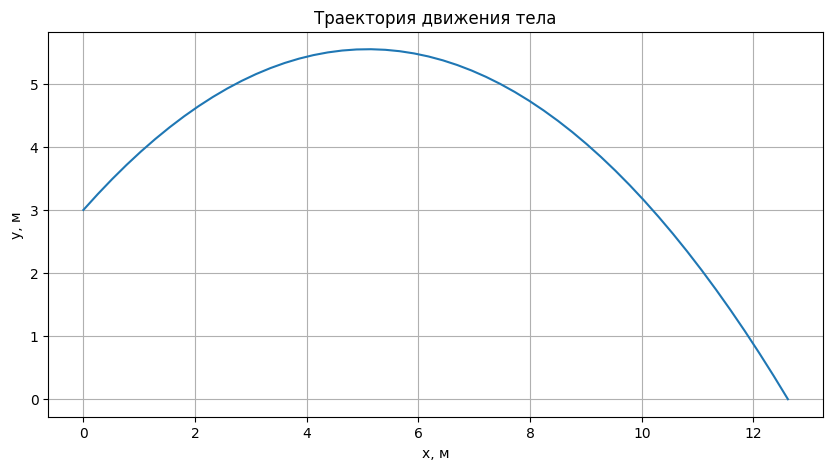

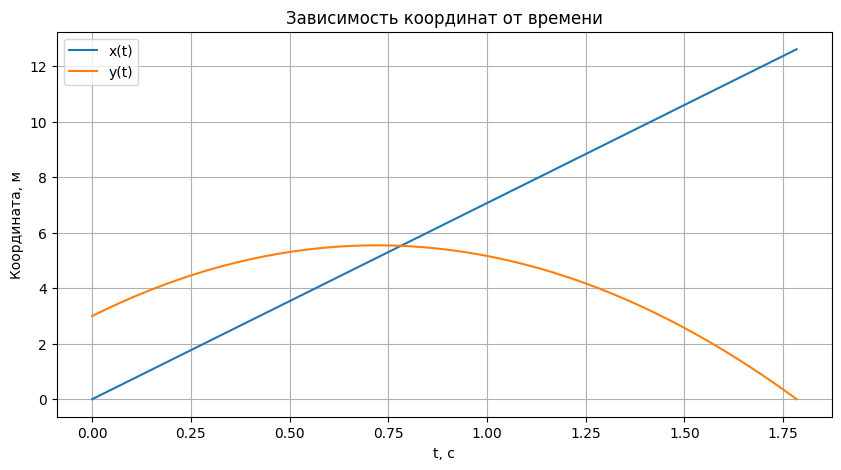

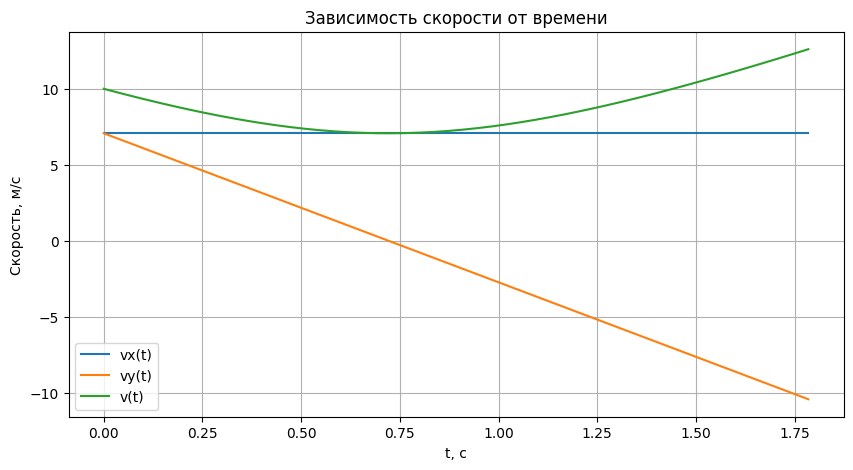

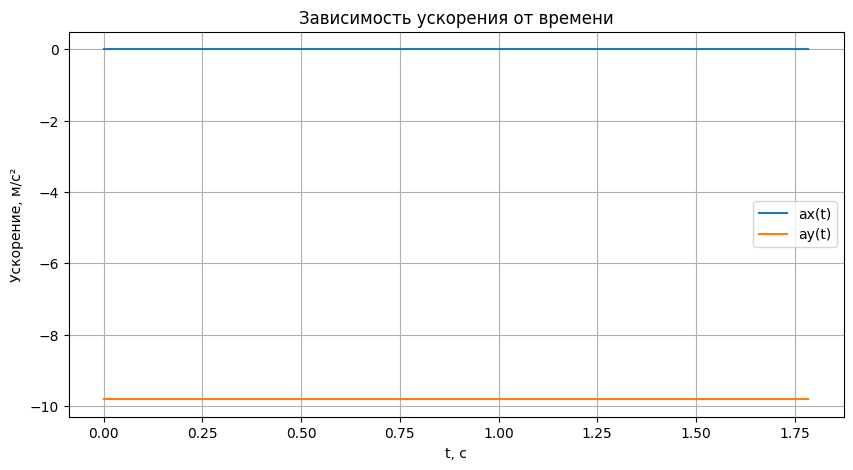

In [ ]:
t_graph = t.detach().numpy()
x_graph = x.detach().numpy()
y_graph = y.detach().numpy()
vx_graph = vx.detach().numpy()
vy_graph = vy.detach().numpy()
v_graph = v.detach().numpy()
ax_graph = ax.detach().numpy()
ay_graph = ay.detach().numpy()

plt.figure(figsize=(10, 5))
plt.plot(x_graph, y_graph)
plt.xlabel("x, м")
plt.ylabel("y, м")
plt.title("Траектория движения тела")
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(t_graph, x_graph, label="x(t)")
plt.plot(t_graph, y_graph, label="y(t)")
plt.xlabel("t, с")
plt.ylabel("Координата, м")
plt.title("Зависимость координат от времени")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(t_graph, vx_graph, label="vx(t)")
plt.plot(t_graph, vy_graph, label="vy(t)")
plt.plot(t_graph, v_graph, label="v(t)")
plt.xlabel("t, с")
plt.ylabel("Скорость, м/с")
plt.title("Зависимость скорости от времени")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(t_graph, ax_graph, label="ax(t)")
plt.plot(t_graph, ay_graph, label="ay(t)")
plt.xlabel("t, с")
plt.ylabel("Ускорение, м/с²")
plt.title("Зависимость ускорения от времени")
plt.grid()
plt.legend()
plt.show()
